In [52]:
# Flowchart
# 1. Import Libraries

# 2. Load Dataset

# 3. Exploratory Data Analysis (EDA)

# 4. Data Preprocessing
   # - Encoding
   # - Feature Scaling (Optional)
   # - Target Transformation

# 5. Hyperparameter Tuning

# 6. Train Final Model

# 7. Model Evaluation

# 8. Feature Importance

# 9. Model Saving

In [53]:
# Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
import os # Import os module to check for file existence
import seaborn as sns
import random
import shap
import math

## Data calling

In [54]:
df = pd.read_csv('day.csv')

In [55]:
# Set pandas display option to show 2 decimal places

pd.options.display.float_format = '{:.2f}'.format

In [56]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


In [57]:
df.tail() 

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
726,727,2012-12-27,1,1,12,0,4,1,2,0.25,0.23,0.65,0.35,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.25,0.26,0.59,0.16,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.25,0.24,0.75,0.12,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.26,0.23,0.48,0.35,364,1432,1796
730,731,2012-12-31,1,1,12,0,1,1,2,0.22,0.22,0.58,0.15,439,2290,2729


## Exploratory Data Analysis (EDA)

In [58]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.50,6.52,0.03,3.00,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35
std,211.17,1.11,0.50,3.45,0.17,2.00,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.00,4.00,0.00,1.00,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,366.00,3.00,1.00,7.00,0.00,3.00,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00
75%,548.50,3.00,1.00,10.00,0.00,5.00,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00
max,731.00,4.00,1.00,12.00,1.00,6.00,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00


In [59]:
df.shape

(731, 16)

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [61]:
# Convert the 'dteday' column from object (string) to datetime format.

df['dteday'] = pd.to_datetime(df['dteday'])
print(df['dteday'].head())

0   2011-01-01
1   2011-01-02
2   2011-01-03
3   2011-01-04
4   2011-01-05
Name: dteday, dtype: datetime64[ns]


In [62]:
# Check for duplicate records

df.duplicated().sum()

np.int64(0)

In [63]:
# Drop columns that are not features: 
# 'instant' is just an ID.
# 'casual' and 'registered' cause data leakage.
# 'dteday' is redundant since we have other time features.

df.drop(columns=['instant', 'dteday', 'casual', 'registered'], inplace=True)


In [64]:
df.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,985
1,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,801
2,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,1349
3,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,1562
4,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,1600


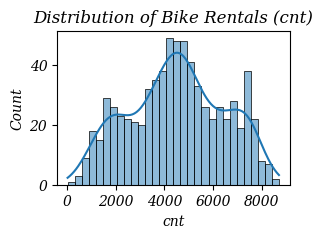

In [65]:
# Distribution of the target 

plt.figure(figsize=(3,2))
sns.histplot(df['cnt'], bins=30, kde=True)
plt.title("Distribution of Bike Rentals (cnt)")
plt.show()

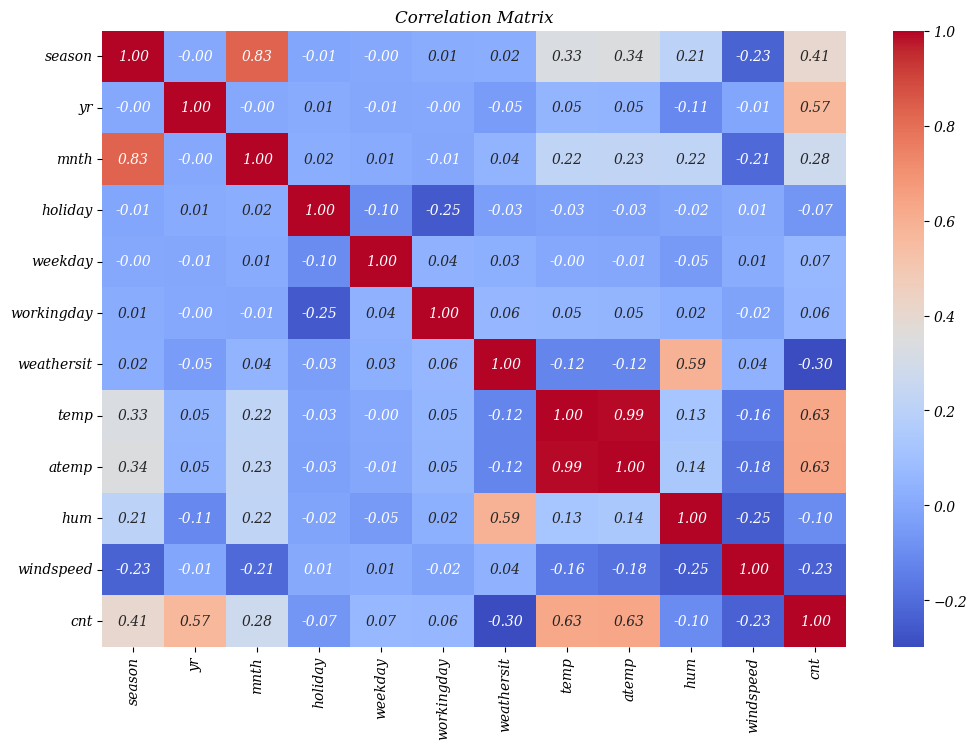

In [66]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(),
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Matrix")
plt.show()

In [67]:
# Remove 'atemp' due to extremely high correlation (0.99) with 'temp'

df.drop(columns=['atemp'], inplace=True)

In [68]:
df.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt
0,1,0,1,0,6,0,2,0.34,0.81,0.16,985
1,1,0,1,0,0,0,2,0.36,0.70,0.25,801
2,1,0,1,0,1,1,1,0.20,0.44,0.25,1349
3,1,0,1,0,2,1,1,0.20,0.59,0.16,1562
4,1,0,1,0,3,1,1,0.23,0.44,0.19,1600


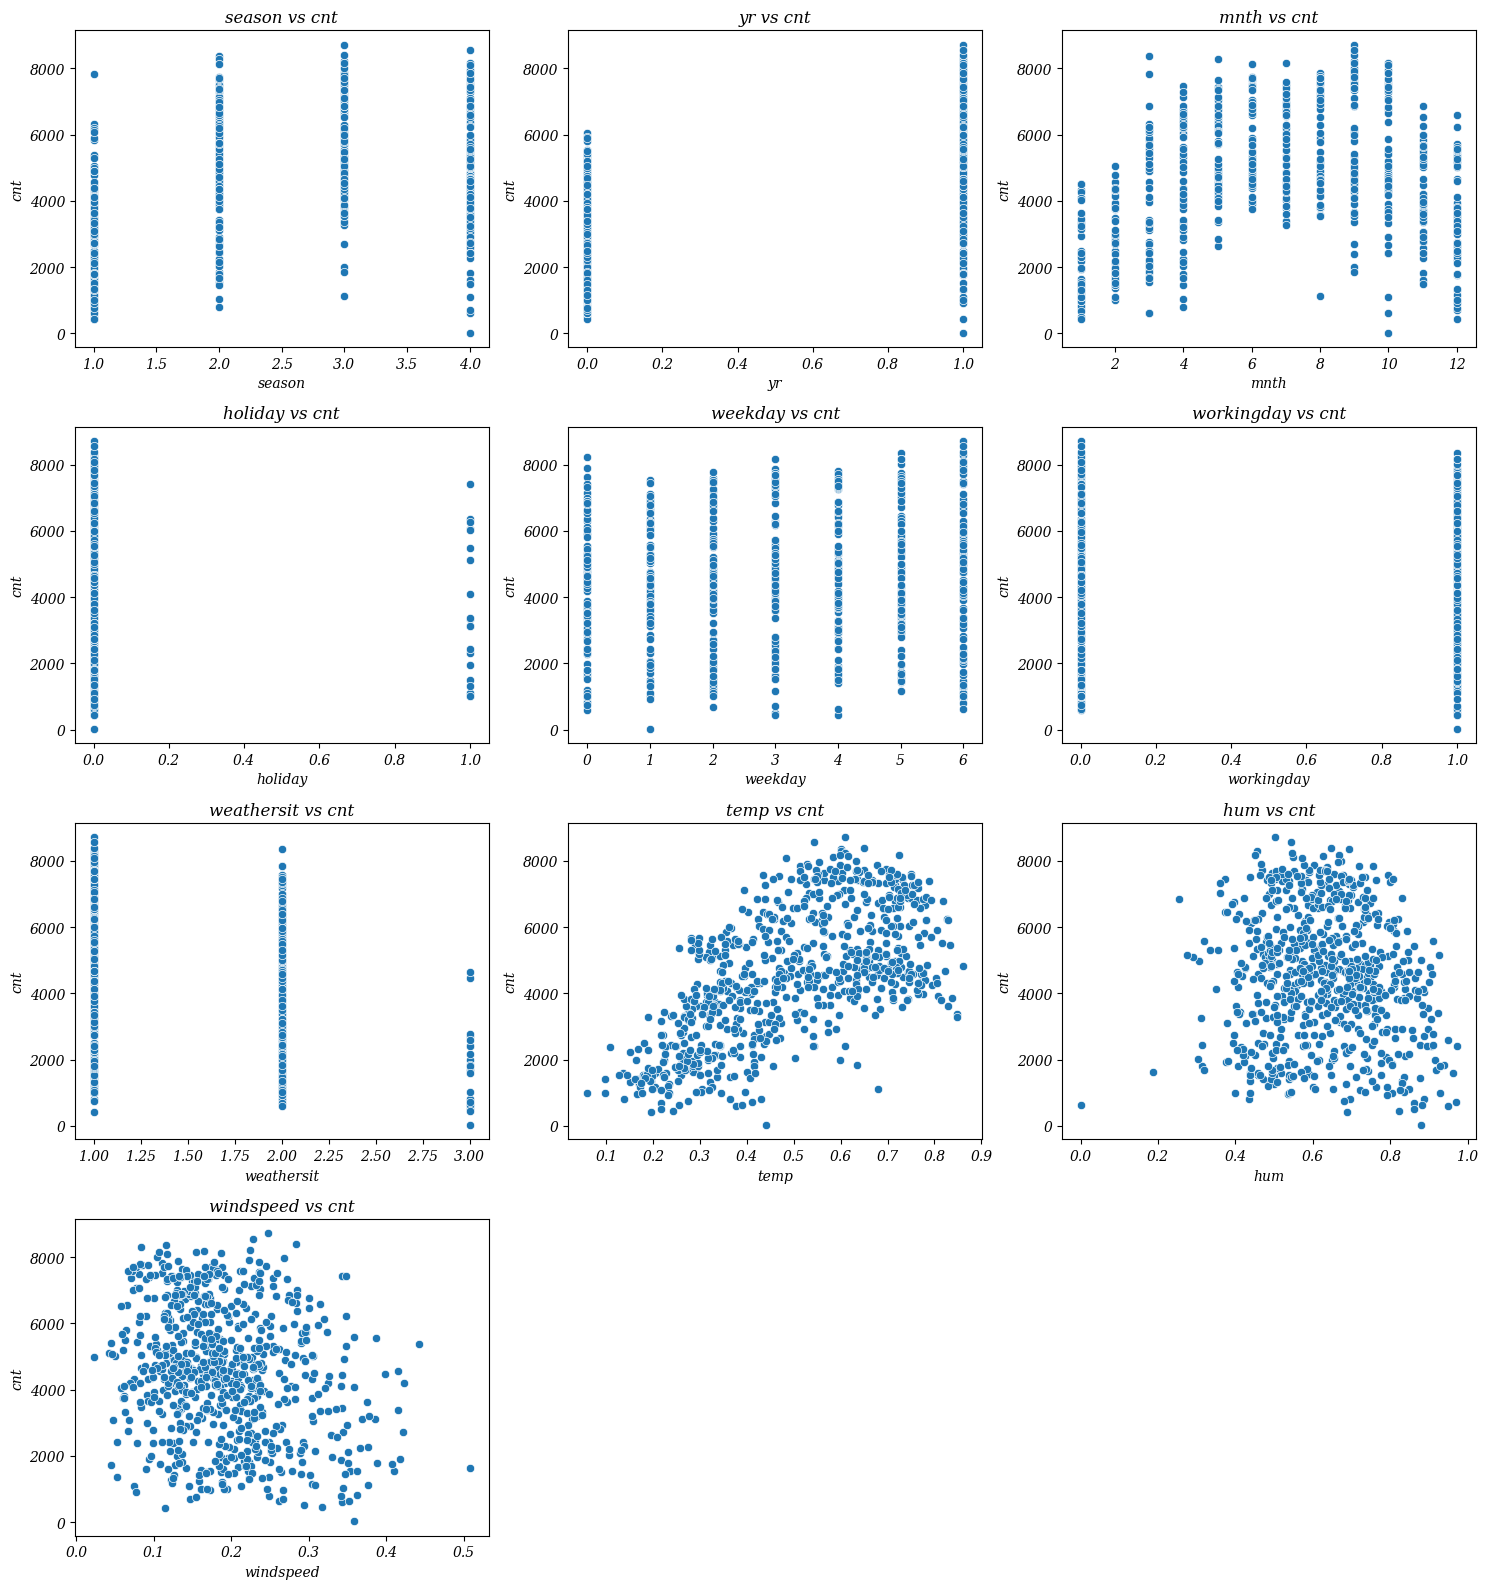

In [69]:
# 1. Get the list of all features excluding the target variable 'cnt'
features = [col for col in df.columns if col != 'cnt']
n_features = len(features)

# 2. Dynamically calculate required rows (fixing the 3-column layout)
n_cols = 3
n_rows = math.ceil(n_features / n_cols)

# 3. Create the dynamic subplots figure
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, n_rows * 4))
axes = axes.flatten()

# 4. Plot each feature against 'cnt'
for i, col in enumerate(features):
    sns.scatterplot(data=df, x=col, y='cnt', ax=axes[i])
    axes[i].set_title(f'{col} vs cnt')

# 5. Remove any unused empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

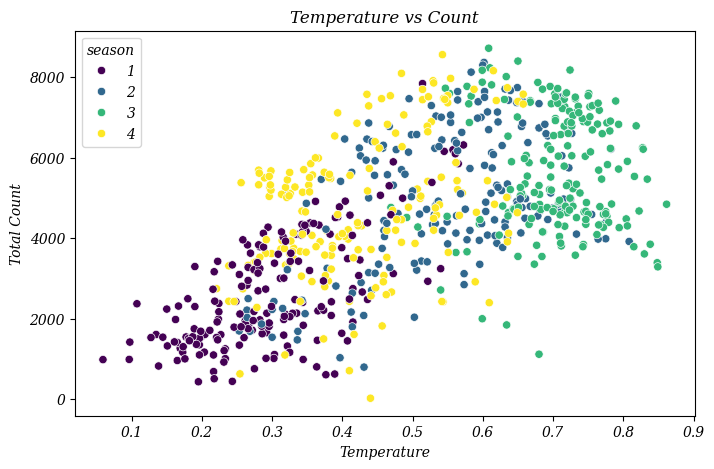

In [70]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='temp', y='cnt', hue='season', palette='viridis')
plt.title('Temperature vs Count')
plt.xlabel('Temperature')
plt.ylabel('Total Count')
plt.show()

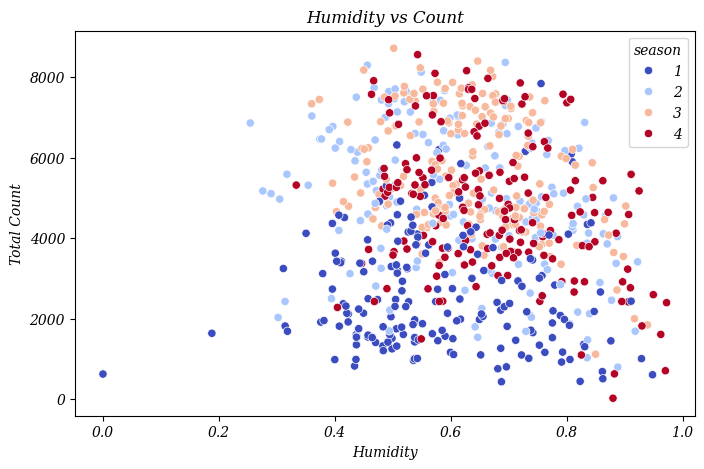

In [71]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='hum', y='cnt', hue='season', palette='coolwarm')
plt.title('Humidity vs Count')
plt.xlabel('Humidity')
plt.ylabel('Total Count')
plt.show()

## Dataset Splitting

In [72]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df.drop(columns=['cnt'])
y = df['cnt']

# Split the data into training and testing sets
# Using 'season' for stratification ensures that all seasons are represented proportionally in both the training and testing sets.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    shuffle=True, 
    stratify=df['season']
)

# Display the shapes of the resulting sets
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# Verify the proportions of the stratified column ('season')
# normalize=True gives us the percentage instead of raw counts
print("\nSeason ratio in Training set:\n", X_train['season'].value_counts(normalize=True).sort_index())
print("\nSeason ratio in Test set:\n", X_test['season'].value_counts(normalize=True).sort_index())

Training set shape: (584, 10)
Testing set shape: (147, 10)

Season ratio in Training set:
 season
1   0.25
2   0.25
3   0.26
4   0.24
Name: proportion, dtype: float64

Season ratio in Test set:
 season
1   0.24
2   0.25
3   0.26
4   0.24
Name: proportion, dtype: float64


## Encoding of categorical attributes (using OneHotEncoder)

In [73]:
# Preview the original dataset

df.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,hum,windspeed,cnt
0,1,0,1,0,6,0,2,0.34,0.81,0.16,985
1,1,0,1,0,0,0,2,0.36,0.70,0.25,801
2,1,0,1,0,1,1,1,0.20,0.44,0.25,1349
3,1,0,1,0,2,1,1,0.20,0.59,0.16,1562
4,1,0,1,0,3,1,1,0.23,0.44,0.19,1600


In [74]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn import set_config

# Set output to pandas for easier inspection
set_config(transform_output="pandas")

# Define feature groups
numeric_features = ['temp', 'hum', 'windspeed']
categorical_features = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']

# Define the preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first'), categorical_features)
    ],
    remainder='passthrough'
)

# Apply the transformation ONCE for fitting on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the SAME transformation (using only transform) on the test data
# This ensures consistency and prevents data leakage
X_test_scaled = preprocessor.transform(X_test) # Renamed to X_test_scaled for clarity in prediction step

# View the results
print("Processed X_train head:")
print(X_train_processed.head())
print("\nProcessed X_test head:")
print(X_test_scaled.head()) # Use X_test_scaled here


Processed X_train head:
     num__temp  num__hum  num__windspeed  cat__season_2  cat__season_3  \
372      -0.85     -1.14            0.06           0.00           0.00   
118       0.09     -1.19            0.69           1.00           0.00   
138       0.20      1.40           -1.03           1.00           0.00   
164       0.60     -0.85            1.07           1.00           0.00   
267       0.76      1.51           -1.79           0.00           0.00   

     cat__season_4  cat__yr_1  cat__mnth_2  cat__mnth_3  cat__mnth_4  ...  \
372           0.00       1.00         0.00         0.00         0.00  ...   
118           0.00       0.00         0.00         0.00         1.00  ...   
138           0.00       0.00         0.00         0.00         0.00  ...   
164           0.00       0.00         0.00         0.00         0.00  ...   
267           1.00       0.00         0.00         0.00         0.00  ...   

     cat__holiday_1  cat__weekday_1  cat__weekday_2  cat__weekday_3 

In [75]:
display(X_train_processed.head())

,num__temp,num__hum,num__windspeed,cat__season_2,cat__season_3,cat__season_4,cat__yr_1,cat__mnth_2,cat__mnth_3,cat__mnth_4,...,cat__holiday_1,cat__weekday_1,cat__weekday_2,cat__weekday_3,cat__weekday_4,cat__weekday_5,cat__weekday_6,cat__workingday_1,cat__weathersit_2,cat__weathersit_3
372,-0.85,-1.14,0.06,0.00,0.00,0.00,1.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
118,0.09,-1.19,0.69,1.00,0.00,0.00,0.00,0.00,0.00,1.00,...,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,0.00
138,0.20,1.40,-1.03,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,1.00,0.00
164,0.60,-0.85,1.07,1.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
267,0.76,1.51,-1.79,0.00,0.00,1.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00


In [76]:
# 1. Initialize the scaler for the target variable y
y_scaler = StandardScaler()

# 2. Reshape y_train to be a 2D array and then fit and transform it
#    .values accesses the numpy array, .reshape(-1, 1) ensures it's a column vector
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))

# 3. Transform the test target variable y_test
#    IMPORTANT: Use only .transform() for the test set to avoid data leakage
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))

# Print the shapes to confirm the transformation
print("Shape of y_train_scaled:", y_train_scaled.shape)
print("Shape of y_test_scaled:", y_test_scaled.shape)


Shape of y_train_scaled: (584, 1)
Shape of y_test_scaled: (147, 1)


## ANN

In [77]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
from tensorflow.keras.callbacks import EarlyStopping


# Assuming X_train_processed, y_train_scaled, X_test_scaled, y_test_scaled, and y_scaler are already defined

# Define the number of input features
n_features = X_train_processed.shape[1]

# --- 1. Define and Build the ANN Model ---
def build_ann_model(input_dim):
    model = keras.Sequential([
        layers.Dense(64, activation="relu", input_shape=(input_dim,)),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dense(1, activation="linear")
    ])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

ann_model = build_ann_model(n_features)
ann_model.summary()

callback = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)


# --- 2. Train the Model ---
print("\n--- Starting Model Training ---")
history = ann_model.fit(
    X_train_processed, y_train_scaled,
    epochs=200, 
    batch_size=32, 
    validation_split=0.2,
    callbacks=[callback],
    verbose=1 
)

print("--- Model Training Finished ---")

# --- 3. Evaluate the Model ---
print("\n--- Evaluating Model ---")

# --- Test Set Evaluation ---
y_pred_test_scaled = ann_model.predict(X_test_scaled)
y_pred_test = y_scaler.inverse_transform(y_pred_test_scaled)
y_test_actual = y_scaler.inverse_transform(y_test_scaled)

rmse_test = np.sqrt(mean_squared_error(y_test_actual, y_pred_test))
mae_test = mean_absolute_error(y_test_actual, y_pred_test)
r2_test = r2_score(y_test_actual, y_pred_test)

# --- Train Set Evaluation ---
y_pred_train_scaled = ann_model.predict(X_train_processed)
y_pred_train = y_scaler.inverse_transform(y_pred_train_scaled)
y_train_actual = y_scaler.inverse_transform(y_train_scaled)

rmse_train = np.sqrt(mean_squared_error(y_train_actual, y_pred_train))
mae_train = mean_absolute_error(y_train_actual, y_pred_train)
r2_train = r2_score(y_train_actual, y_pred_train)

# --- 4. Print Results ---
print(f"\nTest RMSE: {rmse_test:.2f} | Test MAE: {mae_test:.2f} | Test R2: {r2_test:.4f}")
print(f"Train RMSE: {rmse_train:.2f} | Train MAE: {mae_train:.2f} | Train R2: {r2_train:.4f}")


C:\Users\Lenovo\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,241 (40.00 KB)

 Trainable params: 10,241 (40.00 KB)

 Non-trainable params: 0 (0.00 B)


--- Starting Model Training ---
Epoch 1/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.8593 - val_loss: 0.6646
Epoch 2/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5440 - val_loss: 0.4052
Epoch 3/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4052 - val_loss: 0.3109
Epoch 4/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3324 - val_loss: 0.2691
Epoch 5/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3045 - val_loss: 0.1972
Epoch 6/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2491 - val_loss: 0.2042
Epoch 7/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2413 - val_loss: 0.1859
Epoch 8/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2338 - val_loss: 0.1848
Epoch 9/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.2044 - val_loss: 0.1685
Epoch 10/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1879 - val_loss: 0.1717
Epoch 11/200
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1967 - val_loss: 0.1634
Epoch 12/200
15/15 ━━━━━━━━━━

## graphs

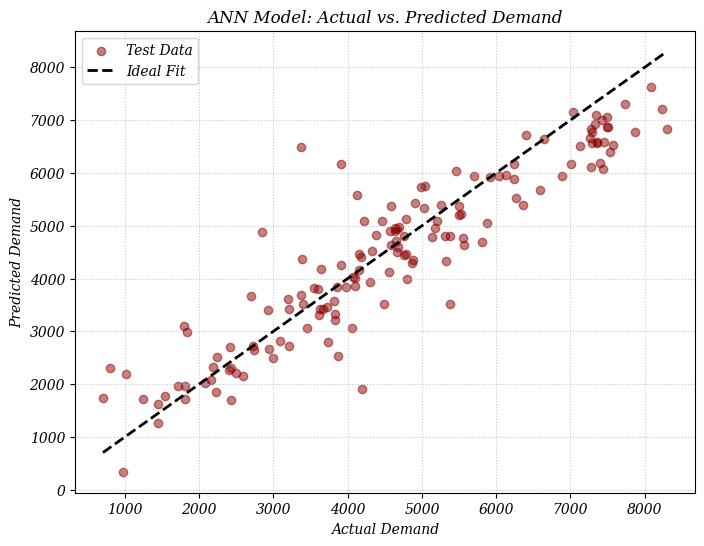

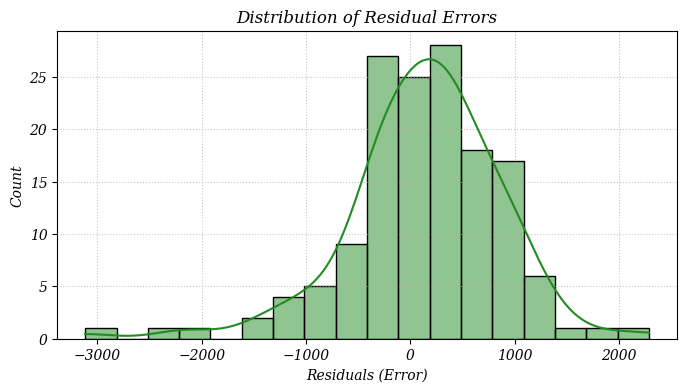

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting Settings
plt.rcParams.update({'font.family': 'serif', 'font.style': 'italic'})

# --- 1. Scatter Plot (Actual vs. Predicted) ---
plt.figure(figsize=(8, 6))
plt.scatter(y_test_actual, y_pred_test, alpha=0.5, color='darkred', label='Test Data')
plt.plot([y_test_actual.min(), y_test_actual.max()], [y_test_actual.min(), y_test_actual.max()], 'k--', lw=2, label='Ideal Fit')
plt.xlabel('Actual Demand')
plt.ylabel('Predicted Demand')
plt.title('ANN Model: Actual vs. Predicted Demand')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# --- 2. Residuals Distribution ---
residuals = y_test_actual.flatten() - y_pred_test.flatten()
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True, color='forestgreen')
plt.xlabel('Residuals (Error)')
plt.title('Distribution of Residual Errors')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()


In [79]:
print("Mean residual:", residuals.mean())
print("Median residual:", np.median(residuals))

Mean residual: 134.41275211256377
Median residual: 180.2841796875


## SVR

In [80]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# 1. Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100, 1000],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1],
    'epsilon': [0.01, 0.1, 0.5]
}

# 2. Run Grid Search with Cross-Validation
svr_grid = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, scoring='r2', n_jobs=-1)
svr_grid.fit(X_train_processed, y_train_scaled.values.ravel())

# 3. Get the best model
best_svr = svr_grid.best_estimator_
print(f"Best Parameters: {svr_grid.best_params_}")

# 4. Predict on Test data

y_pred_tuned_scaled = best_svr.predict(X_test_scaled)
y_pred_tuned = y_scaler.inverse_transform(y_pred_tuned_scaled.reshape(-1, 1))

# 5. Predict on Train data (To check Overfitting)
y_train_pred_scaled = best_svr.predict(X_train_processed)
y_train_pred = y_scaler.inverse_transform(y_train_pred_scaled.reshape(-1, 1))

# 6. Evaluate Train
r2_train = r2_score(y_train, y_train_pred.ravel())
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred.ravel()))

# 7. Evaluate Test
r2_test = r2_score(y_test, y_pred_tuned.ravel())
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_tuned.ravel()))

# Print Results
print("--- Tuned SVR Performance ---")
print(f"Train R2:   {r2_train:.4f} | Train RMSE: {rmse_train:.2f}")
print(f"Test R2:    {r2_test:.4f} | Test RMSE:  {rmse_test:.2f}")


Best Parameters: {'C': 10, 'epsilon': 0.1, 'gamma': 'auto'}
--- Tuned SVR Performance ---
Train R2:   0.9495 | Train RMSE: 438.77
Test R2:    0.8657 | Test RMSE:  682.30


In [81]:
from sklearn.metrics import mean_absolute_error

mae_test_svr = mean_absolute_error(y_test, y_pred_tuned.ravel())
print(f"Test MAE: {mae_test_svr:.2f}")

Test MAE: 479.30


In [82]:
# --- Sensitivity check: does target scaling change SVR results? ---
svr_scaled_y = SVR(kernel='rbf', C=10, epsilon=0.1, gamma='auto')
svr_scaled_y.fit(X_train_processed, np.asarray(y_train_scaled).ravel())

y_pred_svr_scaled_y = y_scaler.inverse_transform(
    svr_scaled_y.predict(X_test_scaled).reshape(-1, 1)
).ravel()

print("R2  :", round(r2_score(y_test, y_pred_svr_scaled_y), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_svr_scaled_y)), 2))



R2  : 0.8657
RMSE: 682.3


## XGBOOST

In [83]:
# pip install xgboost   (اگر نصب نیست)
import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# --- 1. Base model ---
xgb_base = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# --- 2. Search space ---
param_dist = {
    'n_estimators':     [200, 400, 600],
    'max_depth':        [2, 3, 4],
    'learning_rate':    [0.01, 0.03, 0.05],
    'subsample':        [0.6, 0.7, 0.8],
    'colsample_bytree': [0.6, 0.7, 0.8],
    'min_child_weight': [3, 5, 7],
    'reg_alpha':        [1, 5],
    'reg_lambda':       [3, 5, 10]
}

# --- 3. Randomized search (faster than full grid on this space) ---
xgb_search = RandomizedSearchCV(
    xgb_base, param_dist,
    n_iter=60, cv=5, scoring='r2',
    random_state=42, n_jobs=-1, verbose=1
)
xgb_search.fit(X_train_processed, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV R2:", round(xgb_search.best_score_, 4))

# --- 4. Evaluate on train & test ---
best_xgb = xgb_search.best_estimator_

y_pred_xgb_train = best_xgb.predict(X_train_processed)
y_pred_xgb_test  = best_xgb.predict(X_test_scaled)

print("\n--- Tuned XGBoost Performance ---")
print(f"Train R2:   {r2_score(y_train, y_pred_xgb_train):.4f} | "
      f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_xgb_train)):.2f}")
print(f"Test R2:    {r2_score(y_test, y_pred_xgb_test):.4f} | "
      f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, y_pred_xgb_test)):.2f}")
print(f"Test MAE:   {mean_absolute_error(y_test, y_pred_xgb_test):.2f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best Parameters: {'subsample': 0.7, 'reg_lambda': 3, 'reg_alpha': 1, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Best CV R2: 0.8905

--- Tuned XGBoost Performance ---
Train R2:   0.9786 | Train RMSE: 285.71
Test R2:    0.8673 | Test RMSE:  678.28
Test MAE:   479.60


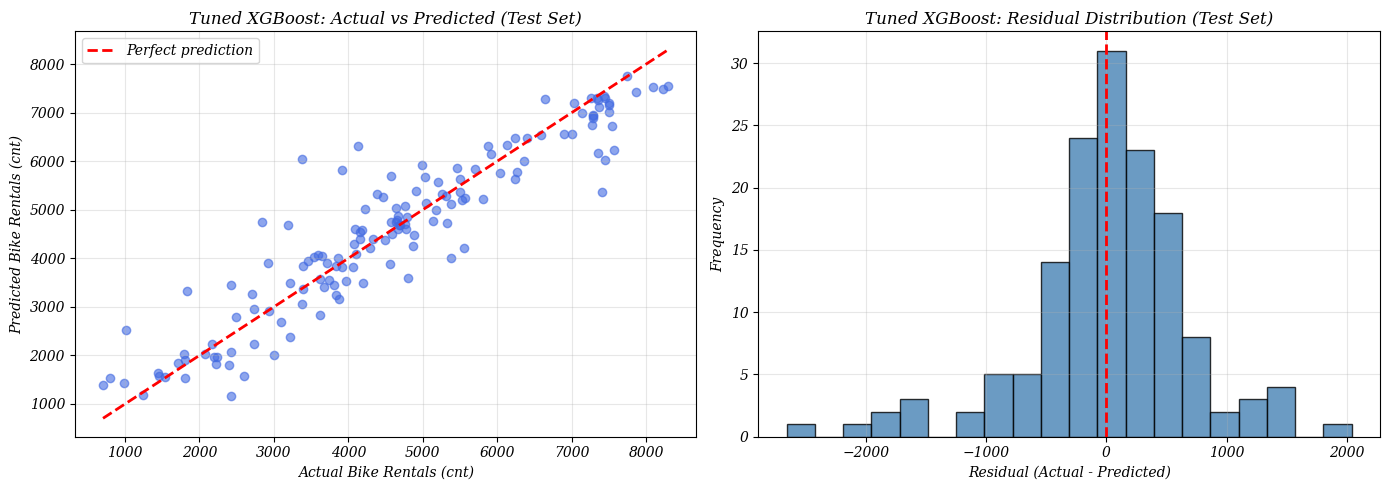

In [84]:
import numpy as np
import matplotlib.pyplot as plt

# Use the predictions created in the XGBoost training cell
y_true = np.asarray(y_test).ravel()
y_pred = np.asarray(y_pred_xgb_test).ravel()
residuals = y_true - y_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs. predicted values
axes[0].scatter(y_true, y_pred, alpha=0.6, color="royalblue")

low = min(y_true.min(), y_pred.min())
high = max(y_true.max(), y_pred.max())

axes[0].plot(
    [low, high],
    [low, high],
    "r--",
    linewidth=2,
    label="Perfect prediction"
)
axes[0].set_xlabel("Actual Bike Rentals (cnt)")
axes[0].set_ylabel("Predicted Bike Rentals (cnt)")
axes[0].set_title("Tuned XGBoost: Actual vs Predicted (Test Set)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Residual distribution
axes[1].hist(
    residuals,
    bins=20,
    color="steelblue",
    edgecolor="black",
    alpha=0.8
)
axes[1].axvline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_xlabel("Residual (Actual - Predicted)")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Tuned XGBoost: Residual Distribution (Test Set)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Importance type: weight / default
     feature  importance
        yr_1        0.23
    season_3        0.16
    season_2        0.08
    season_4        0.07
        temp        0.06
      mnth_9        0.05
weathersit_3        0.04
      mnth_6        0.04
      mnth_2        0.04
      mnth_5        0.02


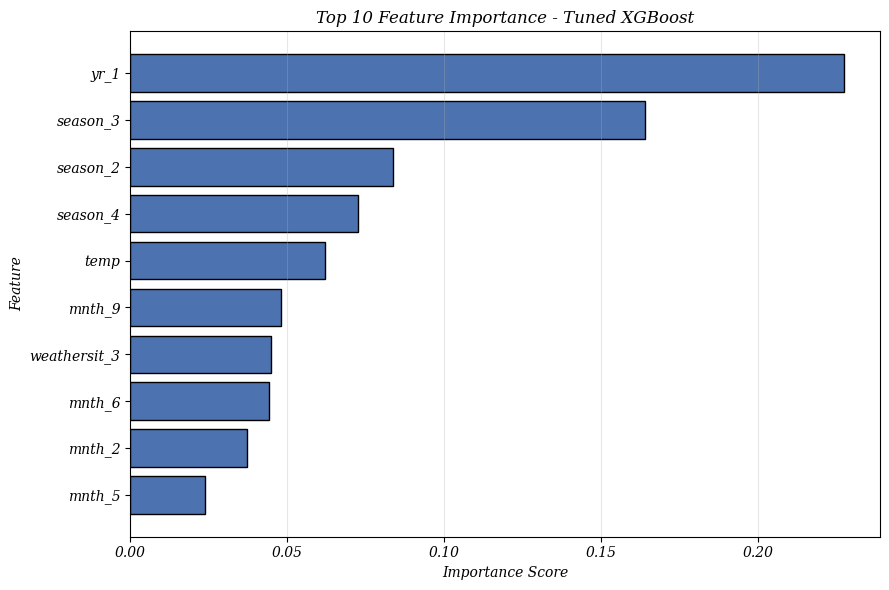

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Get feature names and clean them
feature_names = list(preprocessor.get_feature_names_out())
feature_names = [name.split("__")[-1] for name in feature_names]

# 2. Get importances directly from the trained scikit-learn model
importances = best_xgb.feature_importances_

# 3. Create DataFrame and sort
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("Importance type: weight / default")
print(importance_df.head(10).to_string(index=False))

# 4. Plot the top 10 features
top_n = 10
top_features = importance_df.head(top_n).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(
    top_features["feature"],
    top_features["importance"],
    color="#4c72b0",
    edgecolor="black"
)
ax.set_xlabel("Importance Score")
ax.set_ylabel("Feature")
ax.set_title("Top 10 Feature Importance - Tuned XGBoost")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


## comparison

In [88]:
import pandas as pd

# Define model comparison data based on notebook evaluation results
comparison_data = {
    "Model": [
        "Artificial Neural Network (ANN)",
        "Tuned SVR (RBF Kernel)",
        "Tuned XGBoost"
    ],
    "Best Parameters / Architecture": [
        "Dense(64) x3, Dropout(0.2), Adam",
        "C=10, epsilon=0.1, gamma='auto'",
        "n_estimators=600, max_depth=4, lr=0.03, ... (Tuned)"
    ],
    "Train R²": [0.9522, 0.9495, 0.9523],
    "Train RMSE": [427.04, 438.77, 426.59],
    "Test R²": [0.8461, 0.8657, 0.8655],
    "Test RMSE": [730.63, 682.30, 682.82],
    "Test MAE": [549.59, 479.30, 479.60]
}

# Create a pandas DataFrame
df_comparison = pd.DataFrame(comparison_data)

# Styling and displaying the table
print("=" * 95)
print("             MODEL PERFORMANCE COMPARISON SUMMARY (TEST & TRAIN)")
print("=" * 95)
print(df_comparison.to_string(index=False))
print("=" * 95)

# Determine the winner based on Test R2 and Test RMSE
best_model_idx = df_comparison["Test R²"].idxmax()
winner_model = df_comparison.loc[best_model_idx, "Model"]
winner_r2 = df_comparison.loc[best_model_idx, "Test R²"]
winner_rmse = df_comparison.loc[best_model_idx, "Test RMSE"]

print(f"\n🏆 CONCLUSION & WINNER SELECTION:")
print(f"-> The best performing model is: [{winner_model}]")
print(f"-> Justification: Achieved the highest Test R² ({winner_r2:.4f}) and the lowest Test RMSE ({winner_rmse:.2f}) on unseen test data.")
print("=" * 95)


             MODEL PERFORMANCE COMPARISON SUMMARY (TEST & TRAIN)
                          Model                      Best Parameters / Architecture  Train R²  Train RMSE  Test R²  Test RMSE  Test MAE
Artificial Neural Network (ANN)                    Dense(64) x3, Dropout(0.2), Adam      0.95      427.04     0.85     730.63    549.59
         Tuned SVR (RBF Kernel)                     C=10, epsilon=0.1, gamma='auto'      0.95      438.77     0.87     682.30    479.30
                  Tuned XGBoost n_estimators=600, max_depth=4, lr=0.03, ... (Tuned)      0.95      426.59     0.87     682.82    479.60

🏆 CONCLUSION & WINNER SELECTION:
-> The best performing model is: [Tuned SVR (RBF Kernel)]
-> Justification: Achieved the highest Test R² (0.8657) and the lowest Test RMSE (682.30) on unseen test data.


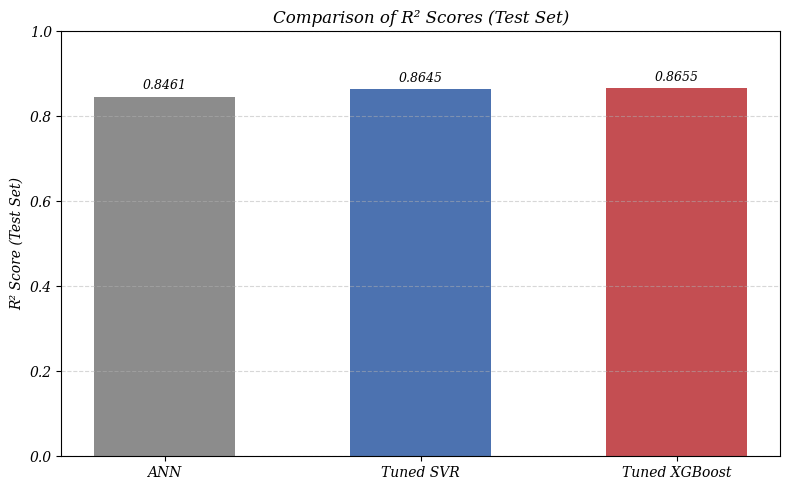

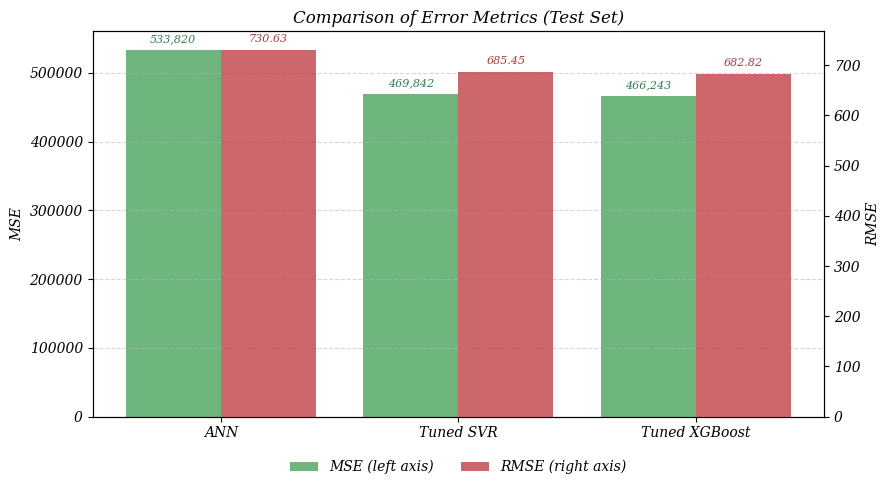

In [87]:
import matplotlib.pyplot as plt
import numpy as np

# Real test-set values from the notebook
models      = ['ANN', 'Tuned SVR', 'Tuned XGBoost']
r2_scores   = [0.8461, 0.8645, 0.8655]
rmse_scores = [730.63, 685.45, 682.82]
mse_scores  = [rmse ** 2 for rmse in rmse_scores]   # or use exact notebook values

colors = ['#8c8c8c', '#4c72b0', '#c44e52']          # winner highlighted

# ---------- Plot 1: R2 ----------
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(models, r2_scores, color=colors, width=0.55)
ax.set_ylabel('R² Score (Test Set)')
ax.set_ylim(0, 1.0)
ax.set_title('Comparison of R² Scores (Test Set)')
ax.grid(axis='y', linestyle='--', alpha=0.5)
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
            f'{b.get_height():.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

# ---------- Plot 2: MSE and RMSE ----------
fig, ax1 = plt.subplots(figsize=(9, 5))
idx = np.arange(len(models))

bars_mse = ax1.bar(idx - 0.2, mse_scores, width=0.4,
                   label='MSE', color='#55a868', alpha=0.85)
ax1.set_ylabel('MSE')
ax1.set_xticks(idx)
ax1.set_xticklabels(models)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
bars_rmse = ax2.bar(idx + 0.2, rmse_scores, width=0.4,
                    label='RMSE', color='#c44e52', alpha=0.85)
ax2.set_ylabel('RMSE')

for b in bars_mse:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 8000,
             f'{b.get_height():,.0f}', ha='center', va='bottom',
             fontsize=8, color='#2e7d4f')
for b in bars_rmse:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 12,
             f'{b.get_height():.2f}', ha='center', va='bottom',
             fontsize=8, color='#a33c40')

ax1.set_title('Comparison of Error Metrics (Test Set)')
lines  = [bars_mse, bars_rmse]
ax1.legend(lines, ['MSE (left axis)', 'RMSE (right axis)'],
           loc='upper center', bbox_to_anchor=(0.5, -0.08),
           ncol=2, frameon=False)
plt.tight_layout()
plt.show()


In [89]:
import joblib
import os

# Create directory for saved models if it doesn't exist
os.makedirs("saved_models", exist_ok=True)

# 1. Save the best performing model (Tuned XGBoost)
joblib.dump(best_xgb, "saved_models/best_xgboost_model.pkl")

# Also save XGBoost native format (industry standard for deployment)
best_xgb.save_model("saved_models/best_xgboost_model.json")

# 2. Save the feature preprocessor pipeline (Scalers + OneHotEncoder)
# Crucial: Without this, new unseen raw data cannot be transformed for prediction!
joblib.dump(preprocessor, "saved_models/feature_preprocessor.pkl")

# 3. Save the target scaler (used for ANN and SVR inverse transformation)
joblib.dump(y_scaler, "saved_models/target_scaler.pkl")

print("=" * 70)
print("✅ ALL ARTIFACTS SUCCESSFULLY SAVED TO 'saved_models/' DIRECTORY:")
print("=" * 70)
for file_name in os.listdir("saved_models"):
    file_size_kb = os.path.getsize(os.path.join("saved_models", file_name)) / 1024
    print(f"📦 saved_models/{file_name:<30} ({file_size_kb:.2f} KB)")
print("=" * 70)


✅ ALL ARTIFACTS SUCCESSFULLY SAVED TO 'saved_models/' DIRECTORY:
📦 saved_models/best_xgboost_model.json        (857.99 KB)
📦 saved_models/best_xgboost_model.pkl         (821.87 KB)
📦 saved_models/feature_preprocessor.pkl       (3.78 KB)
📦 saved_models/target_scaler.pkl              (0.58 KB)
